# Plot color palette for dark and light mode

In [35]:

import matplotlib.pyplot as plt

# ==========================================
# Color palettes
# ==========================================

PLOT_COLORS = {
    "light": [
        "#1762A0",  # 1. Blue
        "#A64600",  # 2. Orange
        "#50565E",  # 3. Gray
        "#7840A4",  # 4. Purple
        "#886000",  # 5. Gold
        "#A12567",  # 6. Pink
        "#347A3D",  # 7. Green
        "#B03A48",  # 8. Red
    ],
    "dark": [
        "#67B4F2",  # 1. Blue
        "#FFAB66",  # 2. Orange
        "#CED3D8",  # 3. Gray
        "#C39BF5",  # 4. Purple
        "#F4D45D",  # 5. Gold
        "#FF91C2",  # 6. Pink
        "#8BDC98",  # 7. Green
        "#FF767F",  # 8. Red
    ]
}

# ==========================================
# Linestyles and markers
# ==========================================

LINESTYLES = [
    "-",                 # 1. Solid
    "--",                # 2. Dashed
    ":",                 # 3. Dotted
    "-.",                # 4. Dash-dot
    (0, (8, 3)),         # 5. Long dashed
    (0, (5, 2, 1, 2)),   # 6. Dash-dot (short)
    (0, (3, 2, 3, 6)),   # 7. Double dashed
    (0, (1, 2, 1, 2, 5, 2)), # 8. Dot-dot-dash
]

MARKERS = [
    "o",  # 1. Circle
    "s",  # 2. Square
    "^",  # 3. Triangle up
    "D",  # 4. Diamond
    "x",  # 5. Cross
    "v",  # 6. Triangle down
    "P",  # 7. Filled plus
    "X",  # 8. Filled X
]

# ==========================================
# Plot setup
# ==========================================

def setup_plot(mode="light"):
    if mode not in PLOT_COLORS:
        raise ValueError("Mode must be 'light' or 'dark'")

    dark = mode == "dark"
    bg = "#17191F" if dark else "#FFFFFF"
    fg = "#F0F0F0" if dark else "#202020"

    plt.rcParams.update({
        "figure.facecolor": bg,
        "axes.facecolor": bg,
        "savefig.facecolor": bg,
        "text.color": fg,
        "axes.labelcolor": fg,
        "xtick.color": fg,
        "ytick.color": fg,
        "axes.edgecolor": fg,
        "grid.alpha": 0.18,
        "axes.prop_cycle": (
            plt.cycler(color=PLOT_COLORS[mode])
            + plt.cycler(linestyle=LINESTYLES)
            + plt.cycler(marker=MARKERS)
        ),
    })

    return PLOT_COLORS[mode]


# ==========================================
# Usage
# ==========================================

colors = setup_plot("dark")

# Automatic cycling:
# ax.plot(x, y1, label="Dataset 1")
# ax.plot(x, y2, label="Dataset 2")
# ...

# Or explicit styling:
# ax.plot(
#     x, y,
#     color=colors[i % 8],
#     linestyle=LINESTYLES[i % 8],
#     marker=MARKERS[i % 8],
#     label=f"Dataset {i+1}"
# )


# Task 1 - Markov Chain histories

Generate two HMC sims with following params:

|Param|A|B|
|-----|-|-|
|$\beta J$|0.1|0.1|
|$\beta h$|0.5|0.5|
|$n_\text{sites}$|5|5|
|$N_\text{md}$|100|4|
|$N$|12,800|12,800|

In [36]:
# Get everything we need from CP03 and revert to fixed trajectory length tau = 1.0
import numpy as np

def hmc_hamiltonian(p, phi, N, beta, J_hat, h):
    """Calc the artificial HMC Hamiltonian"""

    kinetic = 0.5 * (p ** 2)
    potential = 0.5 * phi**2/ (beta * J_hat) - N * np.log(2*np.cosh(beta * h + phi))

    return kinetic + potential

def force(phi, N, beta, J_hat, h):
    """Calc dp/dt from Hamiltonian"""

    return -phi / (beta * J_hat) + N * np.tanh(beta * h + phi)

def leapfrog(p0, phi0, N_md, N, beta, J_hat, h, tau=1.0):
    """Integrate Hamilton equations over a trajectory of length tau=1"""

    if N_md < 1:
        raise ValueError("N_md must be >= 1")
    # epsilon = 1.0 / N_md
    epsilon = tau / N_md

    Pi = float(p0)
    Phi = float(phi0)

    # first half position step
    Phi += 0.5 * epsilon * Pi

    # N_md -1 full steps
    for _ in range(N_md - 1):
        Pi += epsilon * force(Phi, N, beta, J_hat, h)
        Phi += epsilon * Pi

    # Final momentum step
    Pi += epsilon * force(Phi, N, beta, J_hat, h)

    # Final half position step
    Phi += 0.5 * epsilon * Pi

    return Pi, Phi

def hmc_step(phi, N_md, N, beta, J_hat, h, rng):
    """Perform one HMC update of the field phi"""

    # Sample fresh momentum from standard normal distribution
    p0 = rng.normal(0, 1)

    # calc initial Hamiltonian
    H0 = hmc_hamiltonian(p0, phi, N, beta, J_hat, h)

    # propose new state using leapfrog integration
    # pf, phif = leapfrog(p0, phi, N_md, N, beta, J_hat, h)
    # tau = rng.uniform(0.5, 1.5) # randomize trajectory length
    tau = 1.0 # fixed trajectory length
    pf, phif = leapfrog(p0, phi, N_md, N, beta, J_hat, h, tau=tau)

    # calc final Hamiltonian
    Hf = hmc_hamiltonian(pf, phif, N, beta, J_hat, h)

    # Hamiltonian difference
    dH = Hf - H0 

    # Metropolis acceptance step
    if dH <= 0 or rng.random() < np.exp(-dH):
        return phif, True  # accept
    
    return phi, False  # reject

def run_hmc(phi0, N_md, N, beta, J_hat, h, n_therm, n_meas, rng):
    """Run a HMC sim and return field samples and acceptance rate"""

    phi = float(phi0)

    # Thermalization
    for _ in range(n_therm):
        phi, accepted = hmc_step(phi, N_md, N, beta, J_hat, h, rng)

    # Measurement phase
    phi_samples = np.empty(n_meas)
    n_accepted = 0

    for i in range(n_meas):
        phi, accepted = hmc_step(phi, N_md, N, beta, J_hat, h, rng)

        # Store the sample and count acceptance
        phi_samples[i] = phi
        n_accepted += int(accepted)

    acceptance_rate = n_accepted / n_meas

    return phi_samples, acceptance_rate

def magnetization_observable(phi_samples, beta, h):
    """Magnetization per site for each sampled phi value"""
    return np.tanh(beta * h + phi_samples)

In [37]:
# ============================================================
# Task 1: Generate two Markov Chains

N_sites = 5
beta = 1.0
beta_J = 0.1
beta_h = 0.5

J = beta_J / beta
J_hat = J / N_sites
h = beta_h / beta

N_md_vals = [100, 4]

n_therm = 1000
n_meas = 12800

chains = {}

for N_md in N_md_vals:

    rng = np.random.default_rng(seed=42 + N_md)  # Different seed for each chain

    # genedrate HMC field configfs
    phi_samples, acceptance_rate = run_hmc(
        phi0=0.0,
        N_md=N_md,
        N=N_sites,
        beta=beta,
        J_hat=J_hat,
        h=h,
        n_therm=n_therm,
        n_meas=n_meas,
        rng=rng
    )

    # calc magnetization observable
    m_samples = magnetization_observable(phi_samples, beta, h)

    # store results
    chains[N_md] = {
        "phi": phi_samples,
        "m": m_samples,
        "acceptance_rate": acceptance_rate
    }

    print(
        f"N_md={N_md}:",
        f"Acceptance Rate = {acceptance_rate:.4f}, "
        f"Mean Magnetization = {np.mean(m_samples):.4f}"
    )

N_md=100: Acceptance Rate = 0.9997, Mean Magnetization = 0.4933
N_md=4: Acceptance Rate = 0.6461, Mean Magnetization = 0.4913


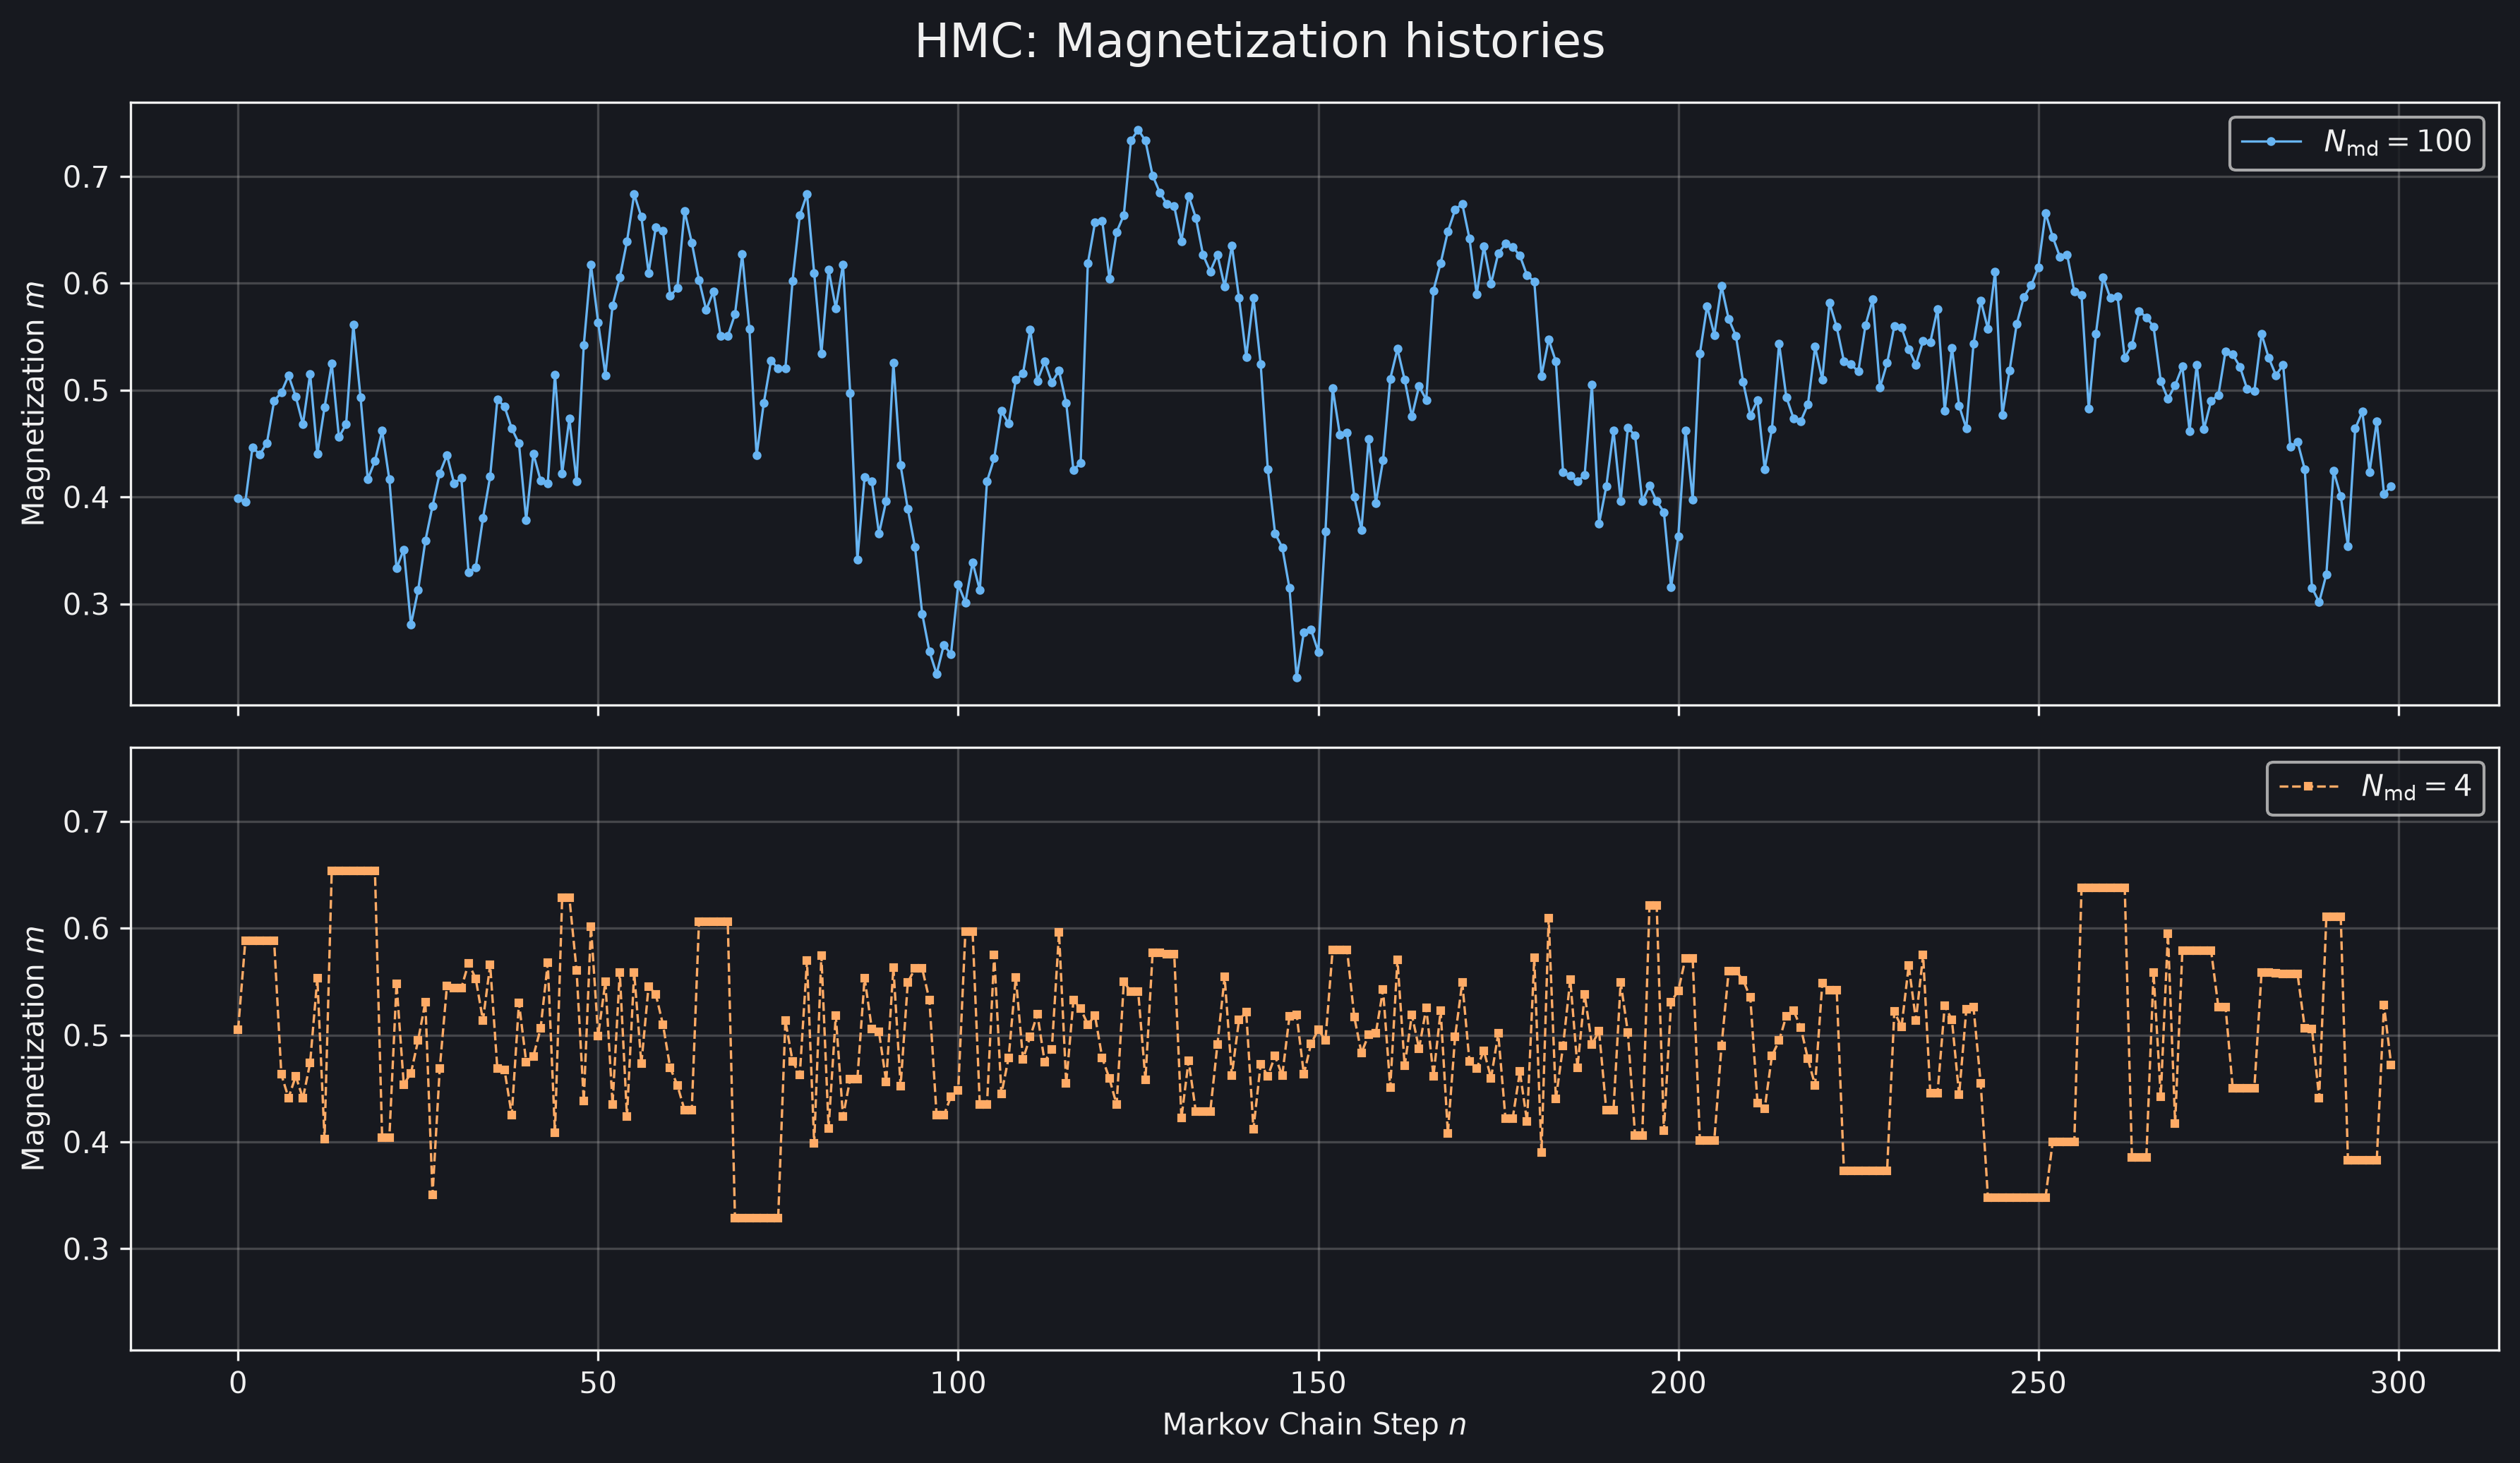

In [38]:
# ==============================================================
# Task 1: Plotting the Markov-chain histories
n_plot = 300

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True, dpi=300)

for i, N_md in enumerate(N_md_vals):
    m_samples = chains[N_md]["m"] # retrieve magnetization samples for this N_md

    axes[i].plot(
        np.arange(n_plot),
        m_samples[:n_plot],
        color=colors[i],
        linestyle=LINESTYLES[i],
        linewidth=0.8,
        marker=MARKERS[i],
        markersize=2,
        label=rf"$N_{{\text{{md}}}}={N_md}$"
    )

    axes[i].set_ylabel(r"Magnetization $m$")
    axes[i].legend()
    axes[i].grid(alpha=0.3)
axes[-1].set_xlabel(r"Markov Chain Step $n$")
fig.suptitle("HMC: Magnetization histories", fontsize=16)
plt.tight_layout()
plt.savefig("figs/hmc_magnetization_histories.pdf", dpi=300)
plt.savefig("figs/hmc_magnetization_histories.png", dpi=300)
plt.show()

# Task 2
Implement autocorrelation estimator $$\boxed{C(\tau) = \frac{\bar{\Gamma}^{(m)}(\tau)}{\bar{\Gamma}^{(m)}(0)}}$$
where $$\bar{\Gamma}^{(m)}(\tau) = \frac{1}{N-\tau} \sum_{k=0}^{N-\tau-1}\left( m_k-\bar{m} \right)\left( m_{k+\tau}-\bar{m} \right).$$

$\tau$ represents lag in Markov-chain steps.
- $C(0) = 1$ per definition
- $C(1)$ measures correlation between consecutive measurements
- $C(\tau) \rightarrow 0$ as separation increases (provided chain loses memory of a better life)

In [39]:
# ==============================================================
# Task 2: define autocorrelation function

def autocorrelation(m_samples, lag):
    """Calc normalized autocorr at given lag"""

    m_samples = np.asarray(m_samples)
    N = len(m_samples)

    # Validate the lag
    if not 0 <= lag < N:
        raise ValueError("lag must satisfy 0 <= lag < N")
    
    # mean magnetization
    m_mean = np.mean(m_samples)

    # center measurements
    fluctuations = m_samples - m_mean

    # autocovariance at specified lag
    gamma_lag = np.sum(fluctuations[:N - lag] * fluctuations[lag:]) / (N - lag)

    # autocovariance at lag zero
    gamma_0 = np.sum(fluctuations**2) / N

    # normalized autocorrelation
    return gamma_lag / gamma_0

N_md=100:C(0) = 1.0000,C(1) = 0.8608,C(10) = 0.2098
N_md=4:C(0) = 1.0000,C(1) = 0.5955,C(10) = 0.2042


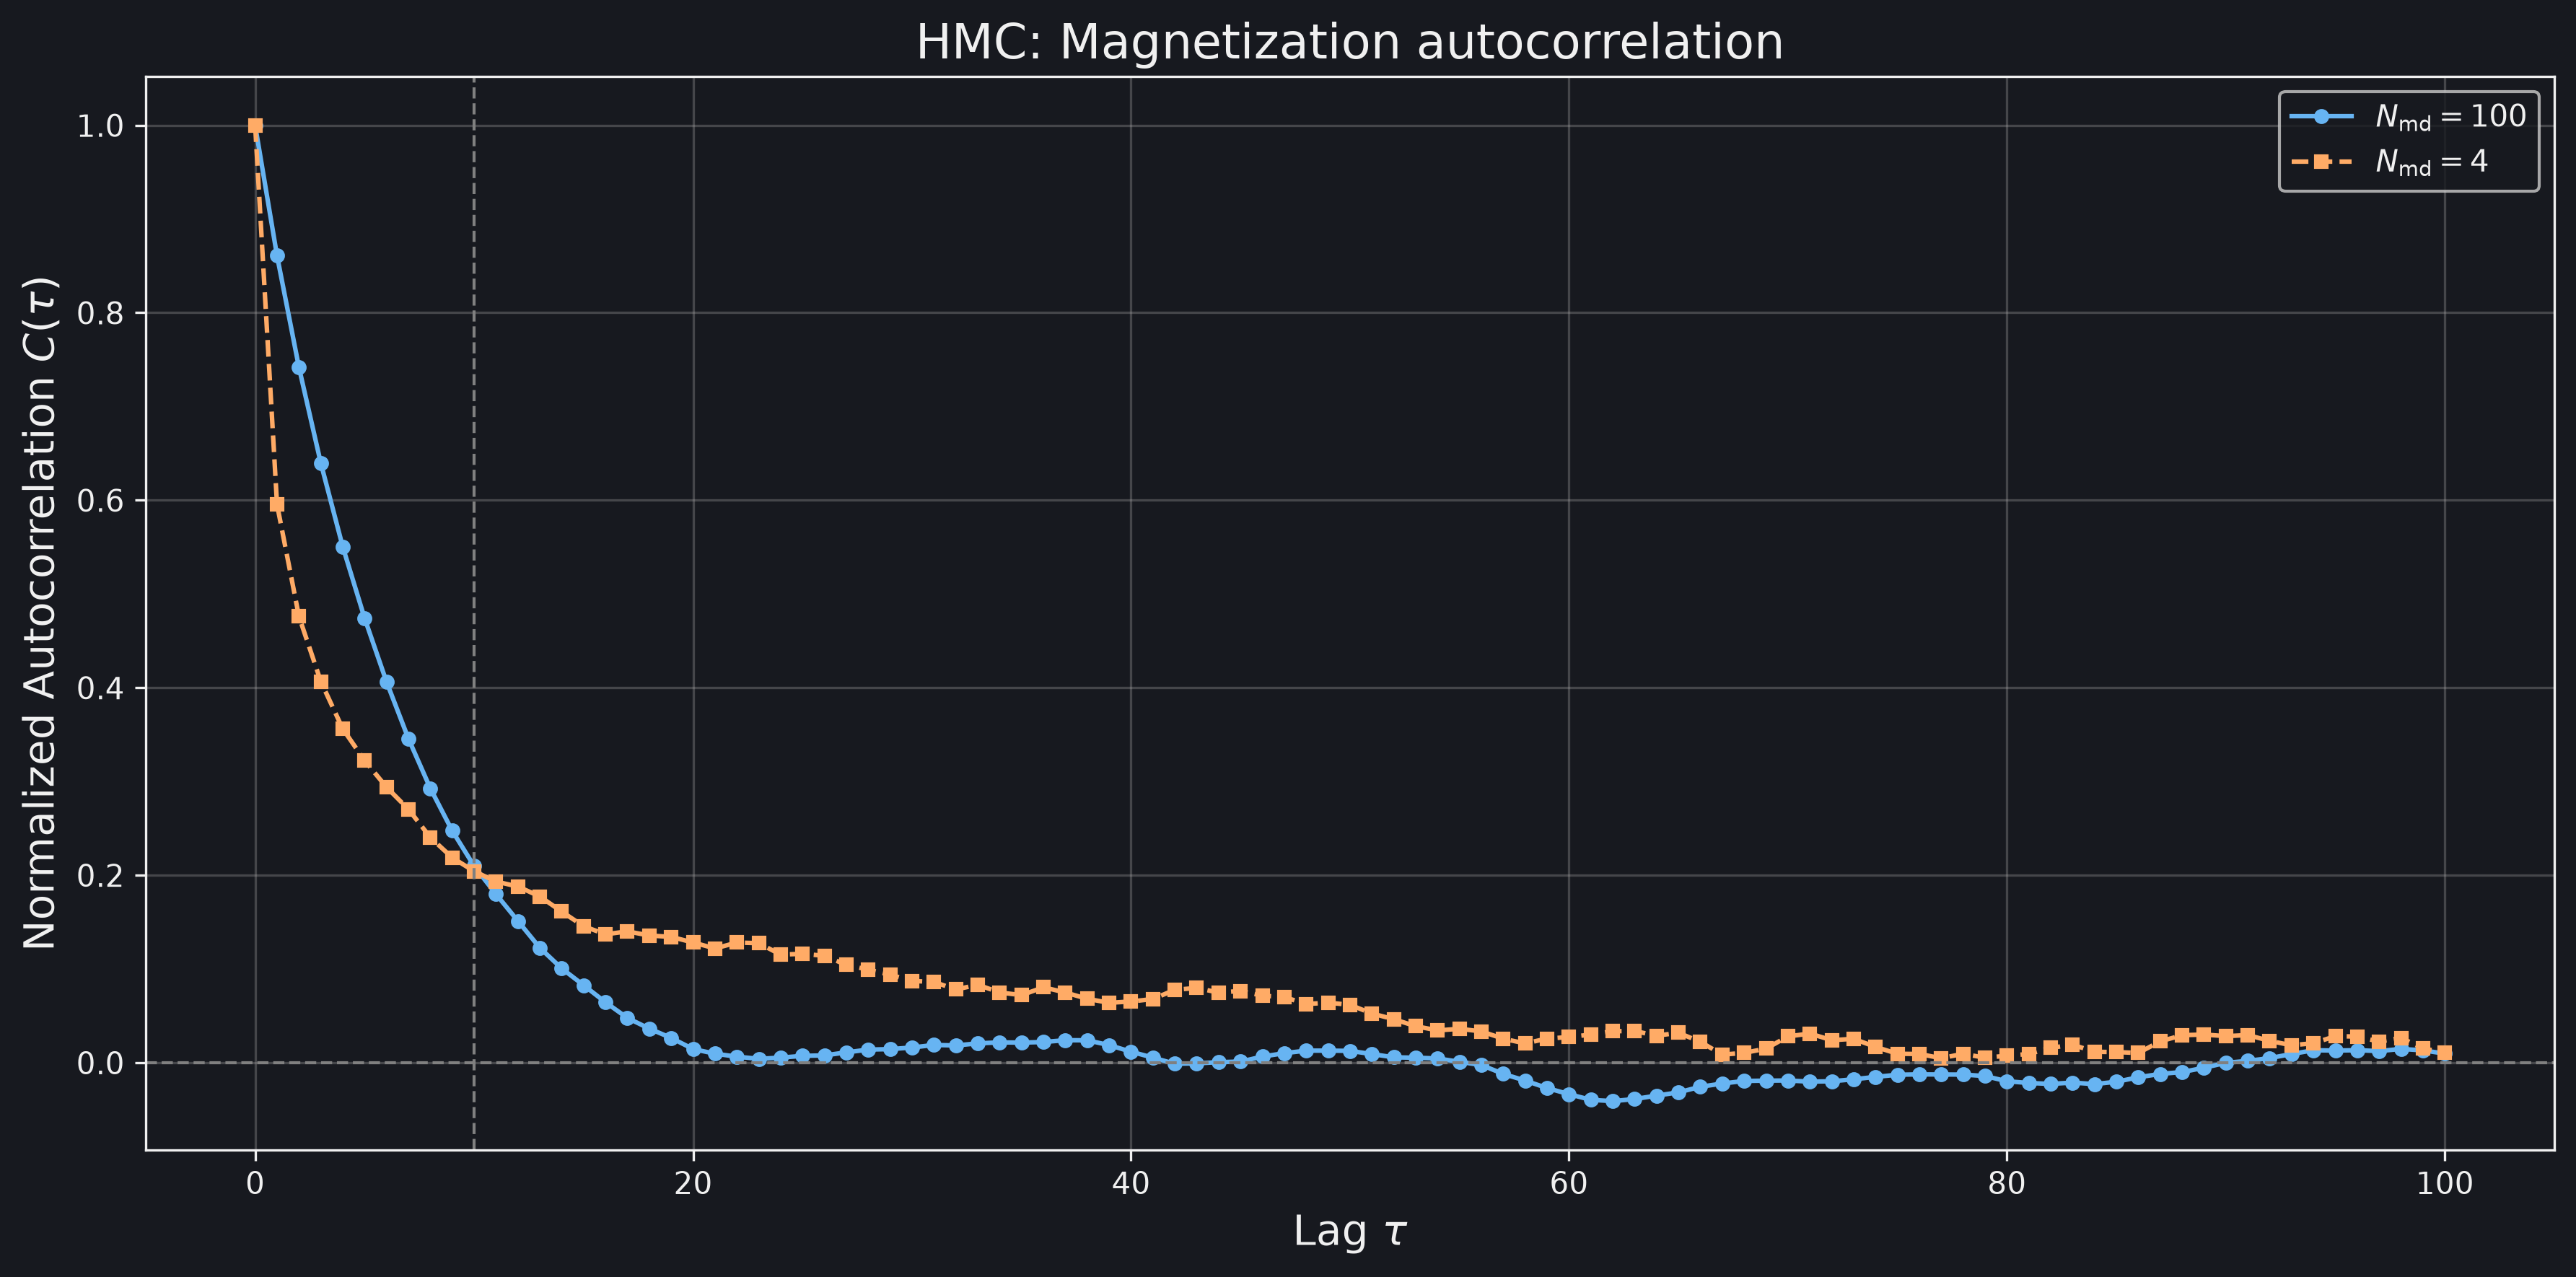

In [42]:
# ==============================================================
# Task 2: plot normalized autocorrelation function for each chain

max_lag = 100
lags = np.arange(max_lag + 1)

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

for i, N_md in enumerate(N_md_vals):

    # retrieve magnetisation samples
    m_samples = chains[N_md]["m"]

    # calc autocorr at each lag
    C_vals = np.array([autocorrelation(m_samples, lag) for lag in lags])

    ax.plot(
        lags,
        C_vals,
        color=colors[i],
        linestyle=LINESTYLES[i],
        linewidth=1.5,
        marker=MARKERS[i],
        markersize=4,
        label=rf"$N_{{\text{{md}}}}={N_md}$"
    )
    print(
        f"N_md={N_md}:"
        f"C(0) = {C_vals[0]:.4f},"
        f"C(1) = {C_vals[1]:.4f}," 
        f"C(10) = {C_vals[10]:.4f}"
    )
ax.axhline(0, color="gray", linestyle="--", linewidth=1.0)
ax.axvline(10, color="gray", linestyle="--", linewidth=1.0)
ax.set_xlabel(r"Lag $\tau$", fontsize=14)
ax.set_ylabel(r"Normalized Autocorrelation $C(\tau)$", fontsize=14)
ax.set_title("HMC: Magnetization autocorrelation", fontsize=16)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("figs/hmc_magnetization_autocorrelation.pdf", dpi=300)
plt.savefig("figs/hmc_magnetization_autocorrelation.png", dpi=300)
plt.show()

# Task 3
Take chain with $N_{md} = 100$ and create blocked/binned datasets for $b\in [2,4,8,16,32,64]$. 
Calculate $C(\tau)$ for each blocked chain and estimate standard error $$\Delta \bar{m}_\text{naive} = \frac{\sigma}{\sqrt{N/b}}$$

Blocking/binning means dividing Markov chain into consecutive groups of $b$ measurements and replace each group with average.
E.g. our measurements are $${m} = {m_1, m_2, m_3, m_4, m_5, m_6, m_7, m_8}.$$
For block size $b=2$ we obtain $$m_1^{(2)}=\frac{m_1+m_2}{2},\quad m_2^{(2)}=\frac{m_3+m_4}{2}$$
and so on.

```mermaid

flowchart TD
    A("m1")
    B("m2")
    C("m3")
    D("m4")
    E("m5")
    F("m6")
    G("m7")
    H("m8")
    I("Block 1")
    J("Block 2")
    K("Block 3")
    L("Block 4")
    A & B ---- I
    C & D ---- J
    E & F ---- K
    G & H ---- L

```
In general $$\boxed{m_i^{(b)} = \frac{1}{b} \sum_{j=0}^{b-1}m_{ib+j}}$$
with $i = 0,\dots,N/b-1$ using zero-indexing.
The blocked dataset contains $N_b=\frac{N}{b}$ measurements (provided N is divisible by b).

In [43]:
# =============================================================
# Task 3: Blocking magnetization measurements

def block_data(m_samples, b):
    """Divide measurements into consecutive blocks of size b"""

    m_samples = np.asarray(m_samples)
    N = len(m_samples)

    if b < 1 or b > N:
        raise ValueError("Block size b must satisfy 1 <= b <= N")

    # number of complete blocks
    N_blocks = N // b

    # keep only measurements that fit into complete blocks
    trimmed = m_samples[:N_blocks * b]

    # reshape into 2D array where each row is a block
    blocks = trimmed.reshape(N_blocks, b)

    # calc mean of each block
    blocked_means = np.mean(blocks, axis=1)

    return blocked_means

b= 1: N_blocks = 12800, Mean = 0.493260
b= 2: N_blocks =  6400, Mean = 0.493260
b= 4: N_blocks =  3200, Mean = 0.493260
b= 8: N_blocks =  1600, Mean = 0.493260
b=16: N_blocks =   800, Mean = 0.493260
b=32: N_blocks =   400, Mean = 0.493260
b=64: N_blocks =   200, Mean = 0.493260
b= 1:C(0) = 1.0000,C(1) = 0.8608,C(10) = 0.2098
b= 2:C(0) = 1.0000,C(1) = 0.8016,C(10) = 0.0177
b= 4:C(0) = 1.0000,C(1) = 0.6712,C(10) = 0.0145
b= 8:C(0) = 1.0000,C(1) = 0.4730,C(10) = -0.0241
b=16:C(0) = 1.0000,C(1) = 0.2250,C(10) = -0.0066
b=32:C(0) = 1.0000,C(1) = 0.1180,C(10) = 0.0211
b=64:C(0) = 1.0000,C(1) = 0.0659,C(10) = 0.0551


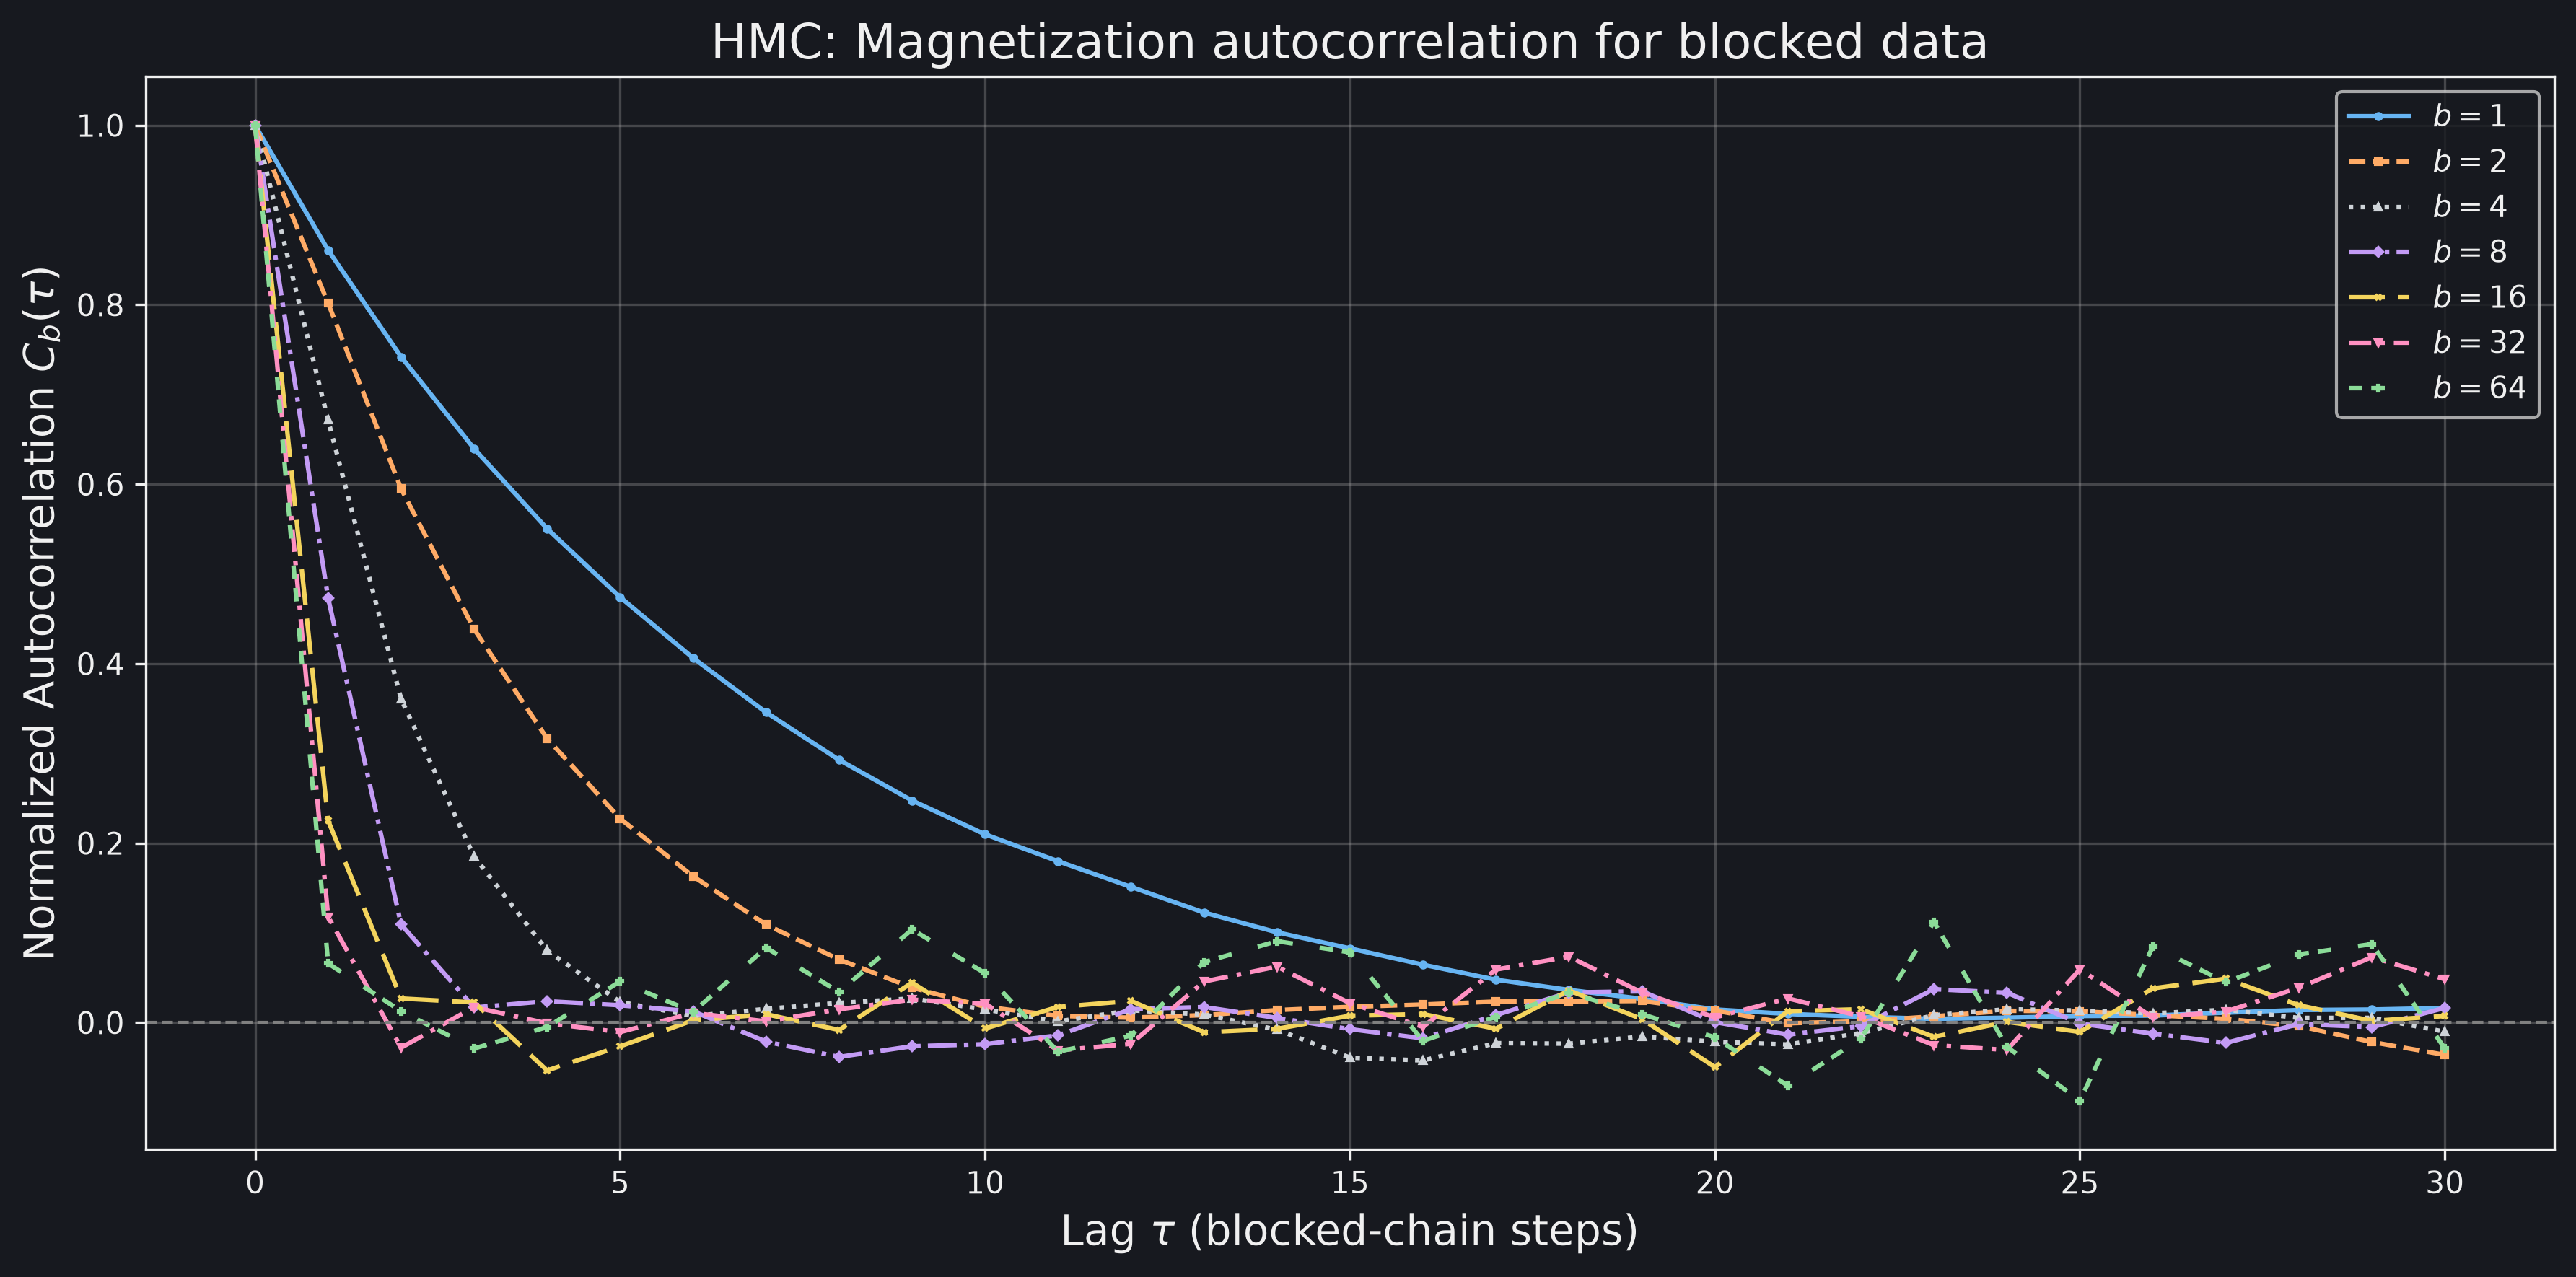

In [46]:
# =============================================================
# Task 3: generate blocked datasets and autocorrelate

# Use N_md = 100 chain
m_samples = chains[100]["m"]

block_sizes = [1, 2, 4, 8, 16, 32, 64]

blocked_data = {}

for b in block_sizes:

    # generate blocked magnetization measurements
    m_blocked = block_data(m_samples, b)

    blocked_data[b] = m_blocked

    print(
        f"b={b:2d}: "
        f"N_blocks = {len(m_blocked):5d}, "
        f"Mean = {np.mean(m_blocked):.6f}"
    )

# Autocorleone
max_lag = 30 # anita max win
lags = np.arange(max_lag + 1)

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

for i, b in enumerate(block_sizes):

    # retrieve blocked magn meas
    m_blocked = blocked_data[b]

    # calc normalized autocorrelation of each lag
    C_val = np.array([autocorrelation(m_blocked, lag) for lag in lags])

    ax.plot(
        lags,
        C_val,
        color=colors[i],
        linestyle=LINESTYLES[i],
        linewidth=1.5,
        marker=MARKERS[i],
        markersize=2,
        label=rf"$b={b}$"
    )
    print(
        f"b={b:2d}:"
        f"C(0) = {C_val[0]:.4f},"
        f"C(1) = {C_val[1]:.4f}," 
        f"C(10) = {C_val[10]:.4f}"
    )
ax.axhline(0, color="gray", linestyle="--", linewidth=1.0)
# ax.axvline(10, color="gray", linestyle="--", linewidth=1.0)
ax.set_xlabel(r"Lag $\tau$ (blocked-chain steps)", fontsize=14)
ax.set_ylabel(r"Normalized Autocorrelation $C_b(\tau)$", fontsize=14)
ax.set_title("HMC: Magnetization autocorrelation for blocked data", fontsize=16)

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("figs/hmc_magnetization_blocked_autocorrelation.pdf", dpi=300)
plt.savefig("figs/hmc_magnetization_blocked_autocorrelation.png", dpi=300)
plt.show()

bing chilling

b= 1: sigma_b = 0.106444, Std Error = 0.000941
b= 2: sigma_b = 0.102715, Std Error = 0.001284
b= 4: sigma_b = 0.097541, Std Error = 0.001724
b= 8: sigma_b = 0.089211, Std Error = 0.002230
b=16: sigma_b = 0.077142, Std Error = 0.002727
b=32: sigma_b = 0.060366, Std Error = 0.003018
b=64: sigma_b = 0.044256, Std Error = 0.003129


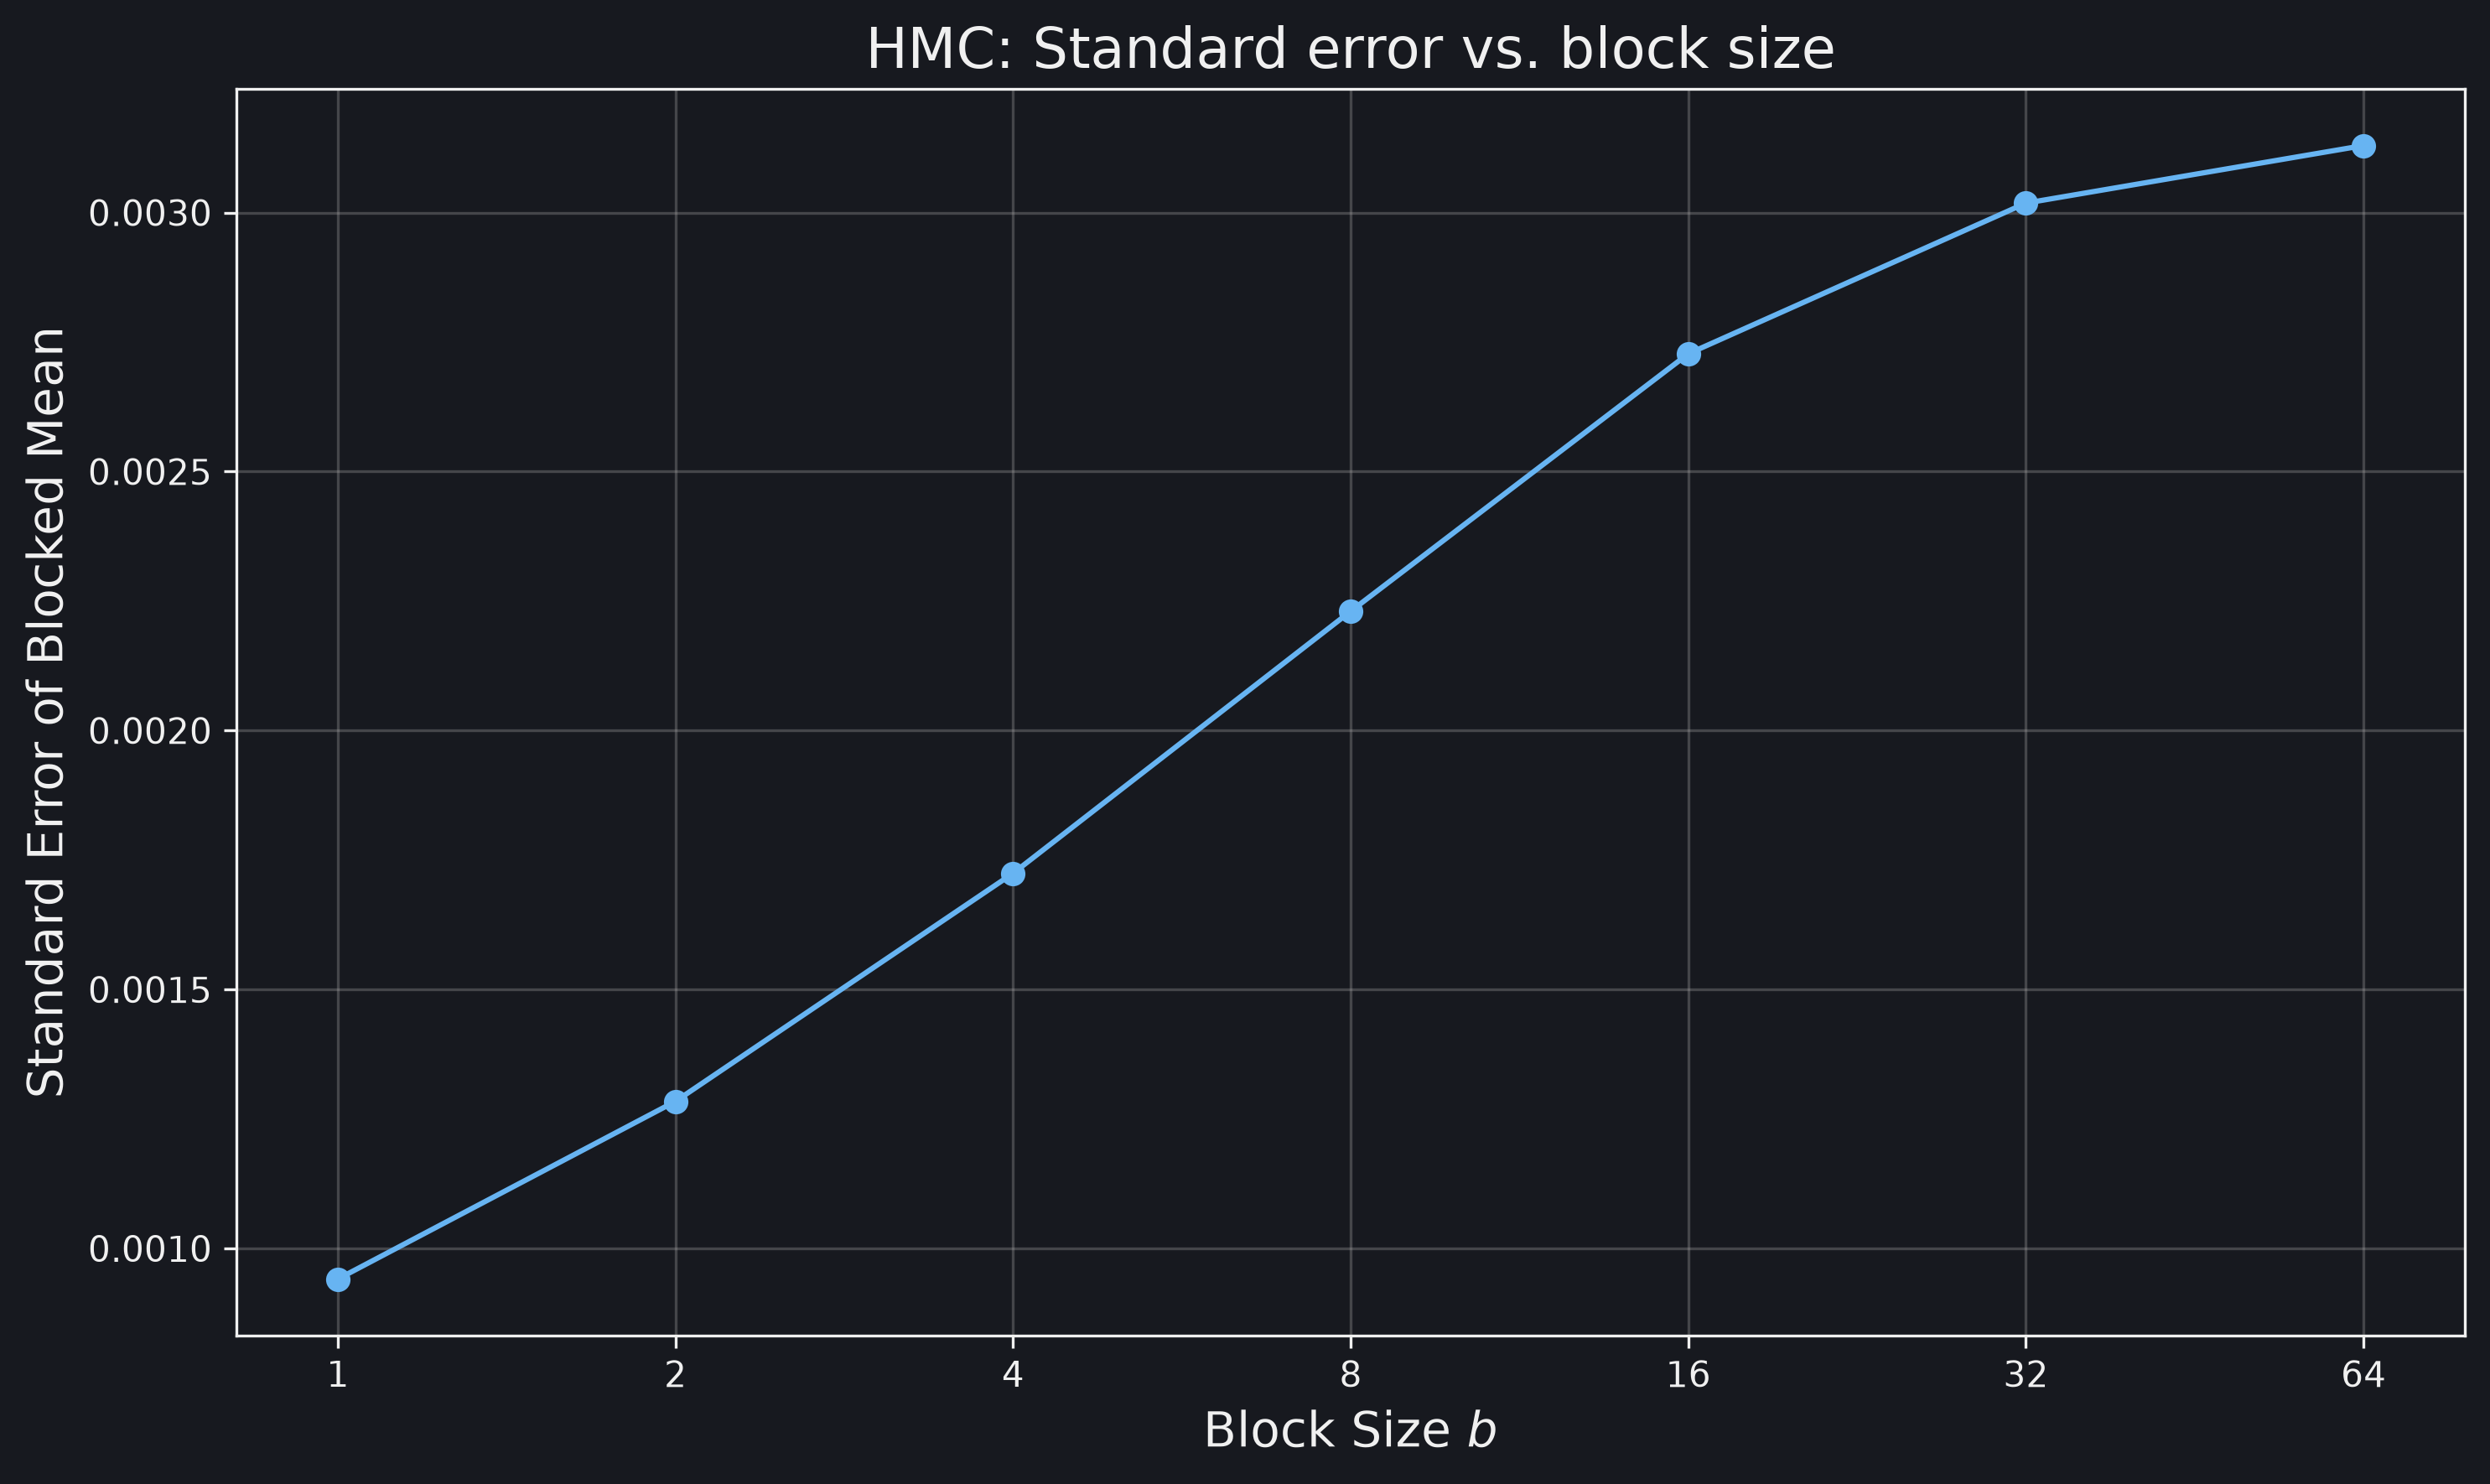

In [53]:
# =============================================================
# Task 3: naive standard error of blocked measurements

standard_errors = []

for b in block_sizes:

    m_blocked = blocked_data[b]

    # number of blocked measurements
    N_blocks = len(m_blocked)

    # sample standard deviation of blocked measurements
    sigma_b = np.std(m_blocked, ddof=1)
    # standard error of the mean
    error_b = sigma_b / np.sqrt(N_blocks)
    standard_errors.append(error_b)

    print(
        f"b={b:2d}: "
        f"sigma_b = {sigma_b:.6f}, "
        f"Std Error = {error_b:.6f}"
    )

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.plot(
    block_sizes,
    standard_errors,
    marker="o",
    linewidth=1.5,
    color=colors[0]
)
ax.set_xscale("log", base=2)
ax.set_xticks(block_sizes)
ax.set_xticklabels(block_sizes)

ax.set_xlabel(r"Block Size $b$", fontsize=14)
ax.set_ylabel(r"Standard Error of Blocked Mean", fontsize=14)
ax.set_title("HMC: Standard error vs. block size", fontsize=16)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figs/hmc_standard_error_vs_block_size.pdf", dpi=300)
plt.savefig("figs/hmc_standard_error_vs_block_size.png", dpi=300)
plt.show()

# Task 4
Code bootstrap procedure and calc statistical bootstrap error for blocked list of ${m}$. Investigate stability of the error as function of $N_{bs}$.

**__Bootstrap procedure:__**

Suppose blocked dataset $$\{m^{(b)}\} = \{ m_0^{(b)}, m_1^{(b)}, \dots, m_{N_b-1}^{(b)} \}$$
We randomly draw $N_b$ values with replacement from this dataset.\
This created a new dataset called bootstrap sample e.g.:


```mermaid
flowchart TD
    subgraph S1 [Original blocked measurements]
        direction LR
        A["0.42"] ~~~ B["0.48"] ~~~ C["0.51"] ~~~ D["0.55"]
    end

    subgraph S2 [Example bootstrap sample]
        direction LR
        E["0.48"] ~~~ F["0.42"] ~~~ G["0.48"] ~~~ H["0.55"]
    end

    S1 -->|Draw four times with replacement| S2
```

